# Lab 3

Este laboratorio se centra en la preparación de datos para un modelo de Machine Learning que desarrollaremos posteriormente.

La limpieza es clave en los modelos: *garbage in -> garbage out*. El modelo tendrá un mal rendimiento si no se garantiza un mínimo de calidad en los datos con los que se le entrena. Veamos distintas fases en la *pipeline* de preparación de datos.

In [278]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

SEED = 1221

### Carga

Vamos a pasar el fichero con los datos, a un DataFrame con Pandas (ver Sprint 0).

In [279]:
df = pd.read_csv("../media/1_lab3/avocado.csv")

Hacemos visualización inicial de los datos.

In [280]:
df.head()

,Unnamed: 0,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,0,2015-12-27,1.33,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.0,conventional,2015,Albany
1,1,2015-12-20,1.35,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.0,conventional,2015,Albany
2,2,2015-12-13,0.93,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.0,conventional,2015,Albany
3,3,2015-12-06,1.08,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.0,conventional,2015,Albany
4,4,2015-11-29,1.28,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.0,conventional,2015,Albany


In [281]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    18249 non-null  int64  
 1   Date          18249 non-null  str    
 2   AveragePrice  18249 non-null  float64
 3   Total Volume  18249 non-null  float64
 4   4046          18249 non-null  float64
 5   4225          18249 non-null  float64
 6   4770          18249 non-null  float64
 7   Total Bags    18249 non-null  float64
 8   Small Bags    18249 non-null  float64
 9   Large Bags    18249 non-null  float64
 10  XLarge Bags   18249 non-null  float64
 11  type          18249 non-null  str    
 12  year          18249 non-null  int64  
 13  region        18249 non-null  str    
dtypes: float64(9), int64(2), str(3)
memory usage: 1.9 MB


Se tienen variables numéricas, y categóricas (type y region)

In [282]:
len(df)

18249

Teniendo en cuenta la longitud del DataFrame, y el número de valores de valores no nulos, se concluye que no existen valores nulos.

In [283]:
df.tail()

,Unnamed: 0,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
18244,7,2018-02-04,1.63,17074.83,2046.96,1529.20,0.00,13498.67,13066.82,431.85,0.0,organic,2018,WestTexNewMexico
18245,8,2018-01-28,1.71,13888.04,1191.70,3431.50,0.00,9264.84,8940.04,324.80,0.0,organic,2018,WestTexNewMexico
18246,9,2018-01-21,1.87,13766.76,1191.92,2452.79,727.94,9394.11,9351.80,42.31,0.0,organic,2018,WestTexNewMexico
18247,10,2018-01-14,1.93,16205.22,1527.63,2981.04,727.01,10969.54,10919.54,50.00,0.0,organic,2018,WestTexNewMexico
18248,11,2018-01-07,1.62,17489.58,2894.77,2356.13,224.53,12014.15,11988.14,26.01,0.0,organic,2018,WestTexNewMexico


Veamos valores únicos en las variables categóricas.

In [284]:
types = df.type.unique().tolist()
regions = df.region.unique().tolist()
print(types)
print(regions)

['conventional', 'organic']
['Albany', 'Atlanta', 'BaltimoreWashington', 'Boise', 'Boston', 'BuffaloRochester', 'California', 'Charlotte', 'Chicago', 'CincinnatiDayton', 'Columbus', 'DallasFtWorth', 'Denver', 'Detroit', 'GrandRapids', 'GreatLakes', 'HarrisburgScranton', 'HartfordSpringfield', 'Houston', 'Indianapolis', 'Jacksonville', 'LasVegas', 'LosAngeles', 'Louisville', 'MiamiFtLauderdale', 'Midsouth', 'Nashville', 'NewOrleansMobile', 'NewYork', 'Northeast', 'NorthernNewEngland', 'Orlando', 'Philadelphia', 'PhoenixTucson', 'Pittsburgh', 'Plains', 'Portland', 'RaleighGreensboro', 'RichmondNorfolk', 'Roanoke', 'Sacramento', 'SanDiego', 'SanFrancisco', 'Seattle', 'SouthCarolina', 'SouthCentral', 'Southeast', 'Spokane', 'StLouis', 'Syracuse', 'Tampa', 'TotalUS', 'West', 'WestTexNewMexico']


In [285]:
len(regions)

54

Existen dos tipos de aguacates, y 54 regiones distintas.

### EDA (Exploratory Data Analysis)

Exploremos y visualicemos los datos para saber con qué estamos trabajando. Hagamos un describe() para ver una pequeño análisis estadístico.

In [286]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,18249.0,24.232232,1.548104e+01,0.00,10.00,24.00,38.00,52.00
AveragePrice,18249.0,1.405978,4.026766e-01,0.44,1.10,1.37,1.66,3.25
Total Volume,18249.0,850644.013009,3.453545e+06,84.56,10838.58,107376.76,432962.29,62505646.52
4046,18249.0,293008.424531,1.264989e+06,0.00,854.07,8645.30,111020.20,22743616.17
4225,18249.0,295154.568356,1.204120e+06,0.00,3008.78,29061.02,150206.86,20470572.61
4770,18249.0,22839.735993,1.074641e+05,0.00,0.00,184.99,6243.42,2546439.11
Total Bags,18249.0,239639.202060,9.862424e+05,0.00,5088.64,39743.83,110783.37,19373134.37
Small Bags,18249.0,182194.686696,7.461785e+05,0.00,2849.42,26362.82,83337.67,13384586.80
Large Bags,18249.0,54338.088145,2.439660e+05,0.00,127.47,2647.71,22029.25,5719096.61
XLarge Bags,18249.0,3106.426507,1.769289e+04,0.00,0.00,0.00,132.50,551693.65


La variable *Unnamed: 0* parece no tener relevancia, la eliminamos.

In [287]:
df = df.drop(columns = "Unnamed: 0")

Ahora con variables categóricas.

In [288]:
df.describe(include = "O").T

/tmp/ipykernel_26133/3878929891.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include = "O").T


,count,unique,top,freq
Date,18249,169,2015-12-27,108
type,18249,2,conventional,9126
region,18249,54,Albany,338


**Visualización**

Hagamos visualizaciones.

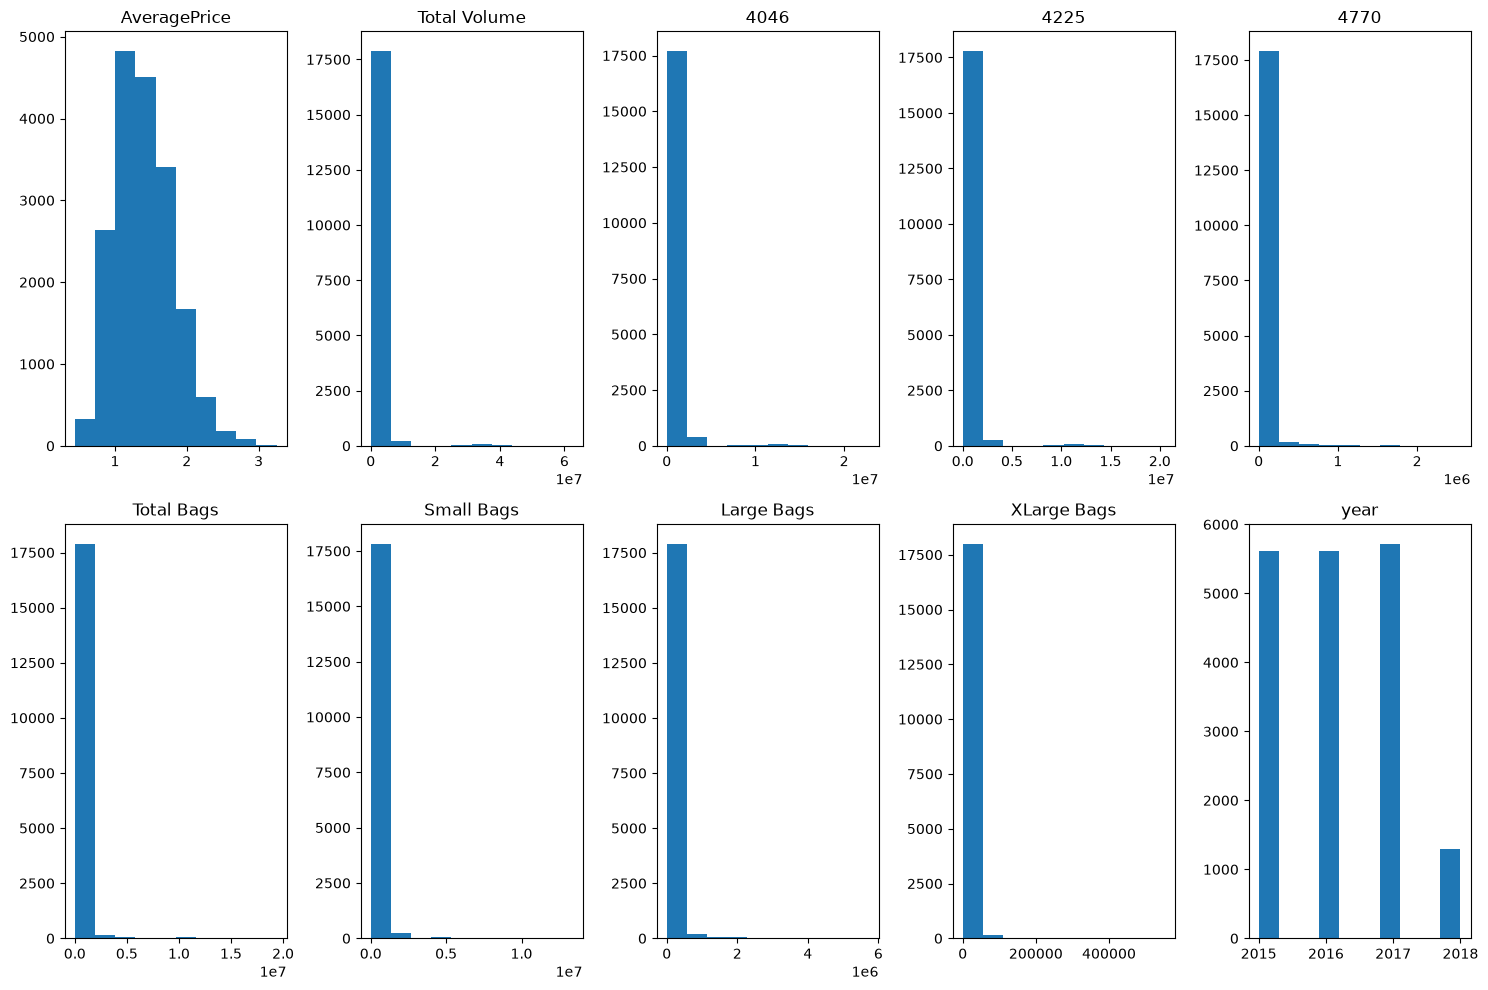

In [ ]:
df.hist(layout = (2, 5), figsize = (15, 10), grid = False)

plt.tight_layout()

Parece ser que con las ventas tenemos valores atípicos en las ventas, hacemos un boxplot.

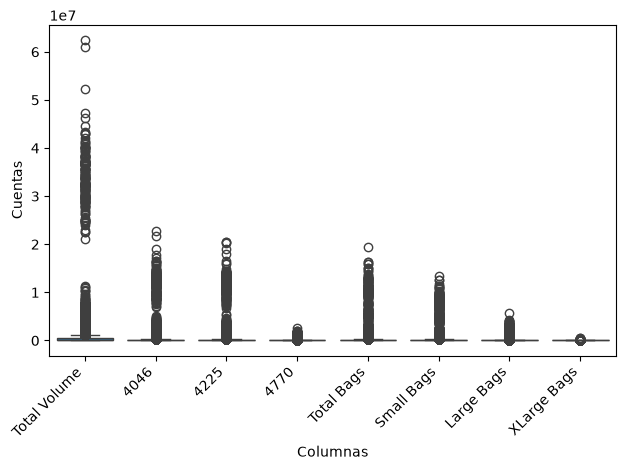

In [290]:
# Fusionamos el DataFrame para que el tamaño de la bolsa sea una categoría
df_melt = pd.melt(df[
    ["Total Volume",
    "4046",
    "4225",
    "4770",
    "Total Bags",
    "Small Bags",
    "Large Bags",
    "XLarge Bags"]
])

sns.boxplot(x = "variable", y = "value", data = df_melt)
plt.xlabel("Columnas")
plt.ylabel("Cuentas")
plt.tick_params("x", rotation = 45, rotation_mode = "xtick")
plt.tight_layout()

Para una mejor visualización.

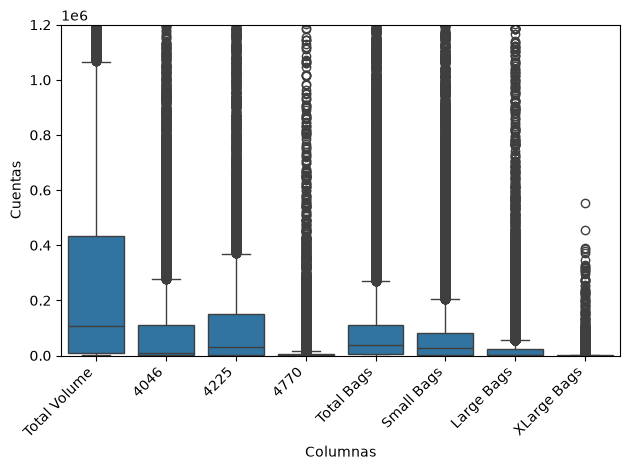

In [291]:
sns.boxplot(x = "variable", y = "value", data = df_melt)
plt.ylim(bottom = 0, top = 1.2e6)
plt.xlabel("Columnas")
plt.ylabel("Cuentas")
plt.tick_params("x", rotation = 45, rotation_mode = "xtick")
plt.tight_layout()

Vemos que hay muchos valores atípicos. Para cada una de estas categorías, vamos a ver cuántos valores se encuentran dentro de los bigotes del boxplot ($Q1 - 1.5 \cdot IQR$, $Q3 + 1.5 \cdot IQR$), en comparación a los que se encuentran fuera.

**Nota**: Solo vamos a usar el rango superior que es el que nos interesa (donde se encuentra la mayoría de outliers)

In [292]:
rates_out_up = []
rates_out_down = []
rates_in = []
lista_cats = [column for column in df.columns.tolist() if ("Bags" in column) | ("Total" in column) | ("4" in column)]

for cat in lista_cats:
    up = df[cat].quantile(0.75) + 1.5 * (df[cat].quantile(0.75) - df[cat].quantile(0.25))
    down = df[cat].quantile(0.25) - 1.5 * (df[cat].quantile(0.75) - df[cat].quantile(0.25))
    n_up = len(df.loc[df[cat] > up])
    n_down = len(df.loc[df[cat] < down])
    n_in =  len(df.loc[(df[cat] <= up) & (df[cat] >= down)])
    rates_out_up.append(n_up / (n_up + n_down + n_in) * 100)
    rates_out_down.append(n_down / (n_up + n_down + n_in) * 100)
    rates_in.append(n_in / (n_up + n_down + n_in) * 100)

out_df = pd.DataFrame({
    "Categoría": lista_cats, 
    "Outliers inferiores (%)": rates_out_down, 
    "Valores dentro de IQR (%)": rates_in,
    "Outliers Superiores (%)": rates_out_up}).set_index("Categoría", inplace = False)
out_df

/tmp/ipykernel_26133/1570455246.py:20: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  "Outliers Superiores (%)": rates_out_up}).set_index("Categoría", inplace = False)


,Outliers inferiores (%),Valores dentro de IQR (%),Outliers Superiores (%)
Categoría,,,
Total Volume,0.0,87.413009,12.586991
4046,0.0,86.201984,13.798016
4225,0.0,86.196504,13.803496
4770,0.0,84.010083,15.989917
Total Bags,0.0,86.119787,13.880213
Small Bags,0.0,86.810236,13.189764
Large Bags,0.0,85.166310,14.833690
XLarge Bags,0.0,78.004274,21.995726


In [293]:
out_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Outliers inferiores (%),8.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Valores dentro de IQR (%),8.0,84.990273,3.004209,78.004274,84.877254,86.158146,86.354047,87.413009
Outliers Superiores (%),8.0,15.009727,3.004209,12.586991,13.645953,13.841854,15.122746,21.995726


Hagamos el Z-score.

In [295]:
def zscore(
    df: pd.DataFrame,
    cols: list
) -> dict:
    """
    Calcula el Z-score de la columna (o columnas) de un dataframe

    :param df: DataFrame
    :param cols: Lista con las columnas
    :return Z-score: Z-score de cada fila para cada columna
    """
    z = {}
    for col in cols:
        serie = df[col]
        media, std = serie.mean(), serie.std()
        z[col] = ((serie - media) / std).to_numpy()
    return z

In [298]:
df.select_dtypes(include = np.number).columns.tolist()

['AveragePrice',
 'Total Volume',
 '4046',
 '4225',
 '4770',
 'Total Bags',
 'Small Bags',
 'Large Bags',
 'XLarge Bags',
 'year']

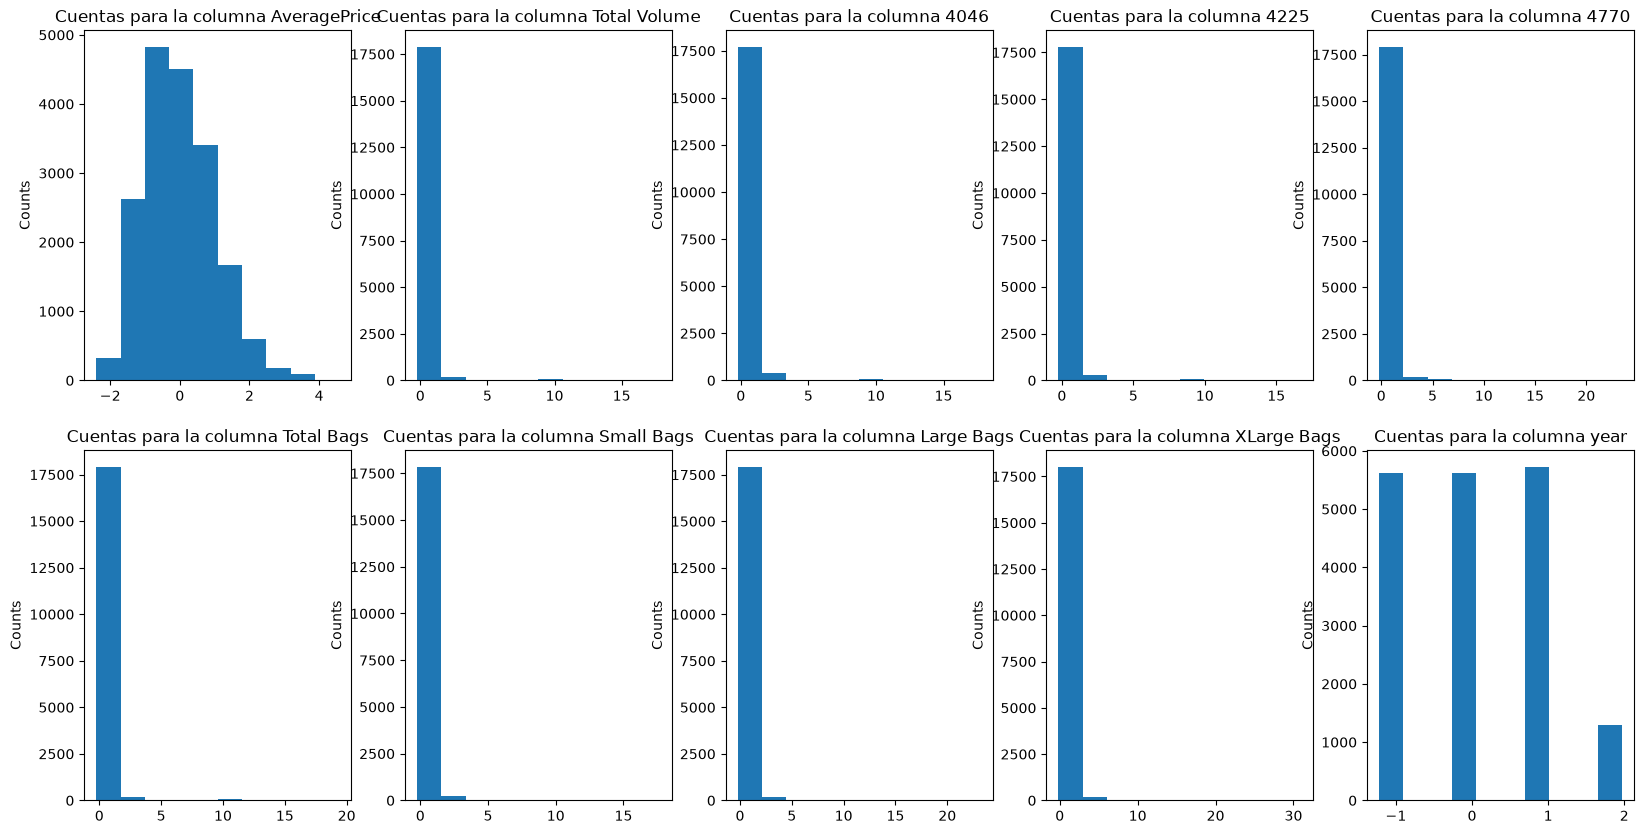

In [300]:
numerical_cols = df.select_dtypes(include = np.number).columns.tolist()
score = zscore(df, numerical_cols)
fig, axes = plt.subplots(nrows = 2, ncols = len(numerical_cols)//2)
fig.set_figwidth(20)
fig.set_figheight(10)
for i, categoria in enumerate(numerical_cols):
    axes.flatten()[i].hist(score[categoria])
    axes.flatten()[i].set_title(f"Cuentas para la columna {categoria}")
    axes.flatten()[i].set_ylabel("Counts")

Hay valores que sobrepasan las 3 desviaciones estándar.

Ahora con las variables categóricas.

In [ ]:
lista_categoricas = df.select_dtypes(include = "O").columns.tolist()
lista_categoricas.remove("Date")

/tmp/ipykernel_26133/688833156.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  lista_categoricas = df.select_dtypes(include = "O").columns.tolist()


['type', 'region']

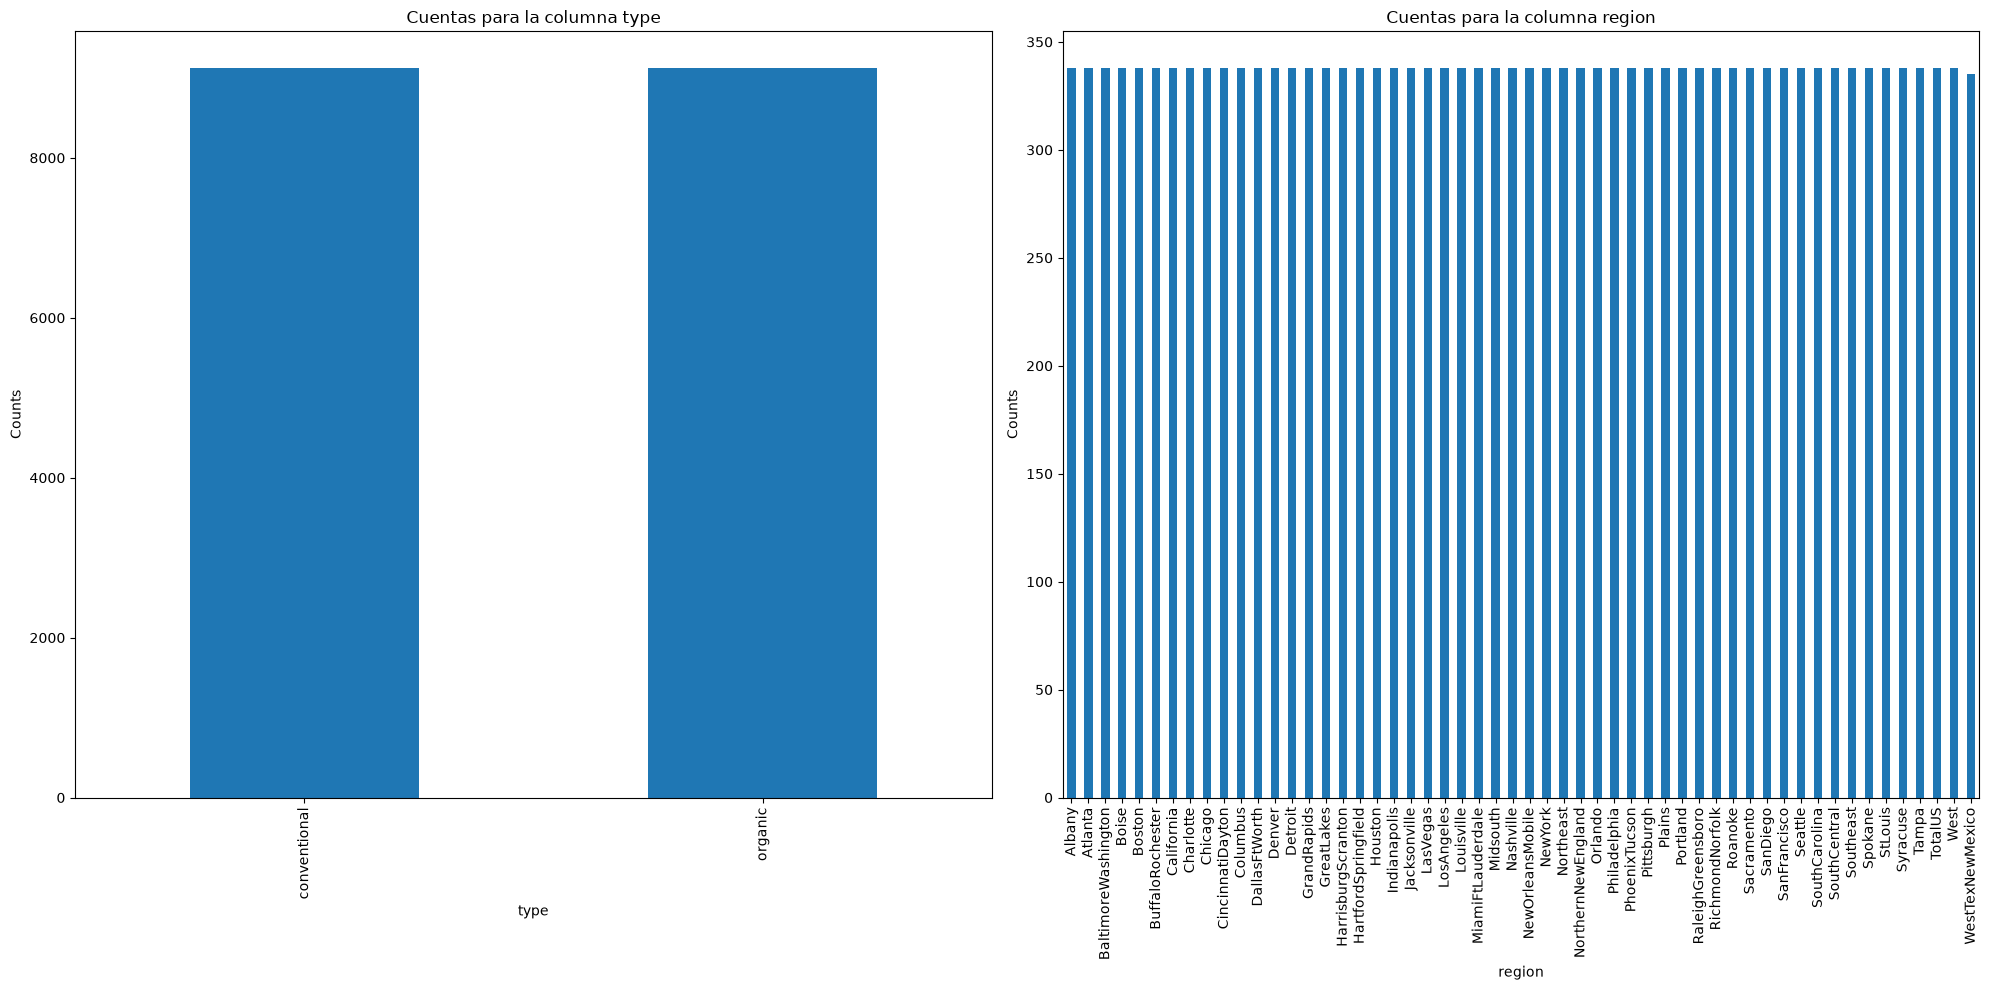

In [ ]:
fig, axes = plt.subplots(nrows = 1, ncols = len(lista_categoricas))
fig.set_figwidth(20)
fig.set_figheight(10)

for i, categoria in enumerate(lista_categoricas):
    df[categoria].value_counts().plot(kind = "bar", ax = axes[i])
    axes[i].set_title(f"Cuentas para la columna {categoria}")
    axes[i].set_ylabel("Counts")

plt.tight_layout()
plt.show()

Vemos que las categóricas están muy balanceadas.

### Limpieza

Corregimos los outliers. Directamente los eliminamos.

In [301]:
df_noouts = df.drop(
    df.loc[
        (df["Total Bags"] >= df["Total Bags"].quantile(0.75) + 1.5 * (df["Total Bags"].quantile(0.75) - df["Total Bags"].quantile(0.25)))
        |
        (df["Small Bags"] > df["Small Bags"].quantile(0.75) + 1.5 * (df["Small Bags"].quantile(0.75) - df["Small Bags"].quantile(0.25)))
        |
        (df["Large Bags"] > df["Large Bags"].quantile(0.75) + 1.5 * (df["Large Bags"].quantile(0.75) - df["Large Bags"].quantile(0.25)))
        |
        (df["XLarge Bags"] > df["XLarge Bags"].quantile(0.75) + 1.5 * (df["XLarge Bags"].quantile(0.75) - df["XLarge Bags"].quantile(0.25)))
        |
        (df["Total Volume"] > df["Total Volume"].quantile(0.75) + 1.5 * (df["Total Volume"].quantile(0.75) - df["Total Volume"].quantile(0.25)))
        |
        (df["4046"] > df["4046"].quantile(0.75) + 1.5 * (df["4046"].quantile(0.75) - df["4046"].quantile(0.25)))
        |
        (df["4225"] > df["4225"].quantile(0.75) + 1.5 * (df["4225"].quantile(0.75) - df["4225"].quantile(0.25)))
        |
        (df["4770"] > df["4770"].quantile(0.75) + 1.5 * (df["4770"].quantile(0.75) - df["4770"].quantile(0.25)))
    ].index
)

Veamos ahora los histogramas.

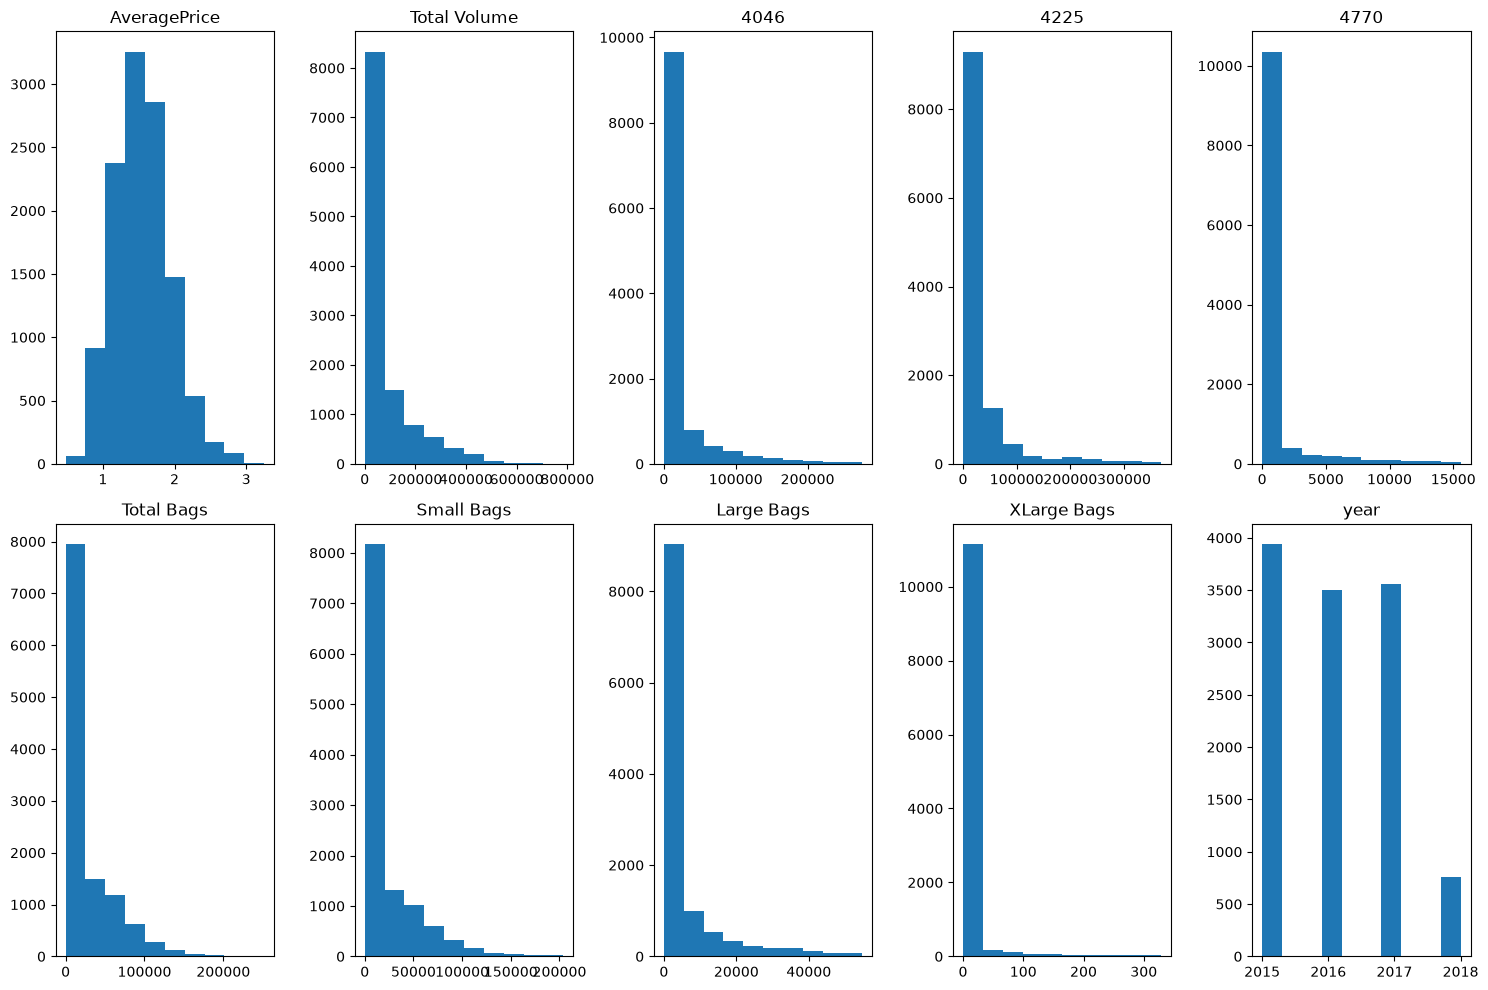

In [302]:
df_noouts.hist(layout = (2, 5), figsize = (15, 10), grid = False)
plt.tight_layout()

Y los boxplots.

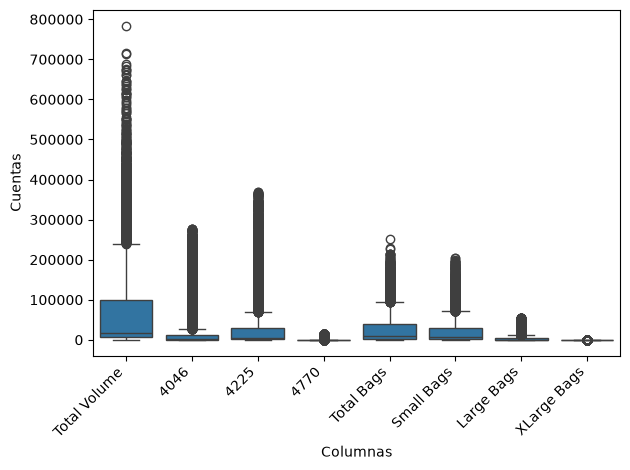

In [ ]:
df_n_melt = pd.melt(df[
    ["Total Volume",
    "4046",
    "4225",
    "4770",
    "Total Bags",
    "Small Bags",
    "Large Bags",
    "XLarge Bags"]
])

sns.boxplot(x = "variable", y = "value", data = df_n_melt)
plt.xlabel("Columnas")
plt.ylabel("Cuentas")
plt.tick_params("x", rotation = 45, rotation_mode = "xtick")
plt.tight_layout()

In [307]:
df.describe() - df_noouts.describe()

,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,year
count,6502.000000,6.502000e+03,6.502000e+03,6.502000e+03,6.502000e+03,6.502000e+03,6.502000e+03,6.502000e+03,6502.000000,6502.000000
mean,-0.144746,7.777523e+05,2.742482e+05,2.672355e+05,2.200732e+04,2.142609e+05,1.618214e+05,4.934031e+04,3099.159612,0.051789
std,0.016367,3.345777e+06,1.223125e+06,1.149007e+06,1.051208e+05,9.521052e+05,7.161649e+05,2.343485e+05,17658.495588,-0.001226
min,-0.040000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000
25%,-0.170000,4.450180e+03,5.672200e+02,1.801005e+03,0.000000e+00,2.678430e+03,1.710240e+03,1.178250e+02,0.000000,0.000000
50%,-0.160000,8.935373e+04,6.938450e+03,2.404383e+04,1.802900e+02,3.126559e+04,2.038434e+04,1.976450e+03,0.000000,0.000000
75%,-0.140000,3.330581e+05,9.990555e+04,1.213329e+05,5.978575e+03,7.118185e+04,5.415610e+04,1.736829e+04,132.500000,0.000000
max,0.000000,6.172173e+07,2.246736e+07,2.010076e+07,2.530865e+06,1.912142e+07,1.318076e+07,5.664322e+06,551364.260000,0.000000


### Transformación

Procedemos al escalado, y codificación de nuevas variables si fuese necesario.

### Train / Test split

Vamos a dividir el set de datos en dos: el conjunto de entrenamiento y el de test. Para comprobar la veracidad del modelo, no podemos usar los datos con los que ha entrenado.